# Mapa Hexagonal de Proximidad Legislativa
---

Este notebook crea visualizaciones tipo 'panal de abejas' donde cada legislador ocupa un hexágono y la proximidad espacial representa proximidad ideológica

## Concepto

- Todos los hexágonos están contiguos (sin espacios)
- La posición relativa indica proximidad ideológica
- Se usa MDS (Multidimensional Scaling) para determinar el orden

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.collections import PatchCollection
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances
import seaborn as sns

In [2]:
# Definir rutas de trabajo
carpeta_legislativas = 'legislativas/'
carpeta_redes = os.path.join(carpeta_legislativas, "diputados", "03_redes")
carpeta_idps = os.path.join(carpeta_legislativas, "diputados", "02_puntos ideales", "idps")

In [3]:
dataset_analisis_redes = pd.read_csv(
    os.path.join(carpeta_redes, "dataframes_grafos_pruned.csv")
)

distancias_idps = pd.read_csv(
    os.path.join(carpeta_idps, "distancias_idps.csv.gz"),
    compression='gzip'
)

## Selección de Legisladores para Análisis

In [4]:
# Definir grupos de interés (ejemplo: 2025)
ANIO_ANALISIS = 2025

# Filtrar datos del año
dataset_2025 = dataset_analisis_redes[dataset_analisis_redes['anio'] == ANIO_ANALISIS].copy()

print(f"Legisladores en {ANIO_ANALISIS}: {len(dataset_2025)}")
print(f"Bloques disponibles:")
print(dataset_2025['bloque'].value_counts())

Legisladores en 2025: 262
Bloques disponibles:
bloque
Union Por La Patria                                              98
La Libertad Avanza                                               37
Pro                                                              36
Encuentro Federal                                                15
Ucr - Union Civica Radical                                       14
Democracia Para Siempre                                          12
Innovacion Federal                                                8
Liga Del Interior Eli                                             6
Coalicion Civica                                                  6
Coherencia                                                        4
Izquierda Socialista Fit-unidad                                   3
Pts-frente De Izquierda Unidad                                    3
Por Santa Cruz                                                    3
Independencia                                                 

In [5]:
# Seleccionar un subconjunto para visualizar (por ejemplo, bloques principales)
# Ajustar según necesidades

# Opción 1: Tomar todos los legisladores
legisladores_seleccionados = dataset_2025['legislador'].tolist()

# Opción 2: Solo ciertos bloques (descomentar para usar)
# bloques_interes = ['La Libertad Avanza', 'Union Por La Patria', 'Ucr - Union Civica Radical']
# legisladores_seleccionados = dataset_2025[
#     dataset_2025['bloque'].isin(bloques_interes)
# ]['legislador'].tolist()

print(f"Legisladores seleccionados: {len(legisladores_seleccionados)}")

Legisladores seleccionados: 262


## Funciones para Coordenadas Hexagonales

In [6]:
def generar_coordenadas_hexagonales(n):
    """
    Genera coordenadas hexagonales en patrón de panal.
    
    Args:
        n: Número de hexágonos necesarios
    
    Returns:
        Lista de tuplas (q, r) en coordenadas axiales hex
    """
    coords = [(0, 0)]  # Centro
    
    # Calcular anillos necesarios
    anillos = int(np.ceil(np.sqrt(n)))
    
    # Direcciones hexagonales
    direcciones = [(1, 0), (0, 1), (-1, 1), (-1, 0), (0, -1), (1, -1)]
    
    for ring in range(1, anillos + 1):
        # Empezar en la posición (ring, -ring)
        q, r = ring, -ring
        
        # Recorrer el anillo
        for direccion in range(6):
            dq, dr = direcciones[direccion]
            for step in range(ring):
                coords.append((q, r))
                q += dq
                r += dr
                
                if len(coords) >= n:
                    return coords[:n]
    
    return coords[:n]

def hex_to_pixel(q, r, size=1.0):
    """
    Convierte coordenadas hexagonales a cartesianas.
    
    Args:
        q, r: Coordenadas axiales hex
        size: Tamaño del hexágono
    
    Returns:
        (x, y) coordenadas cartesianas
    """
    x = size * (np.sqrt(3) * q + np.sqrt(3)/2 * r)
    y = size * (3/2 * r)
    return x, y

def crear_hexagono(x, y, size=1.0):
    """
    Crea un polígono hexagonal.
    
    Args:
        x, y: Centro del hexágono
        size: Tamaño
    
    Returns:
        matplotlib Polygon
    """
    angulos = np.linspace(0, 2*np.pi, 7) + np.pi/6  # +pi/6 para flat-top
    vertices = [(x + size * np.cos(a), y + size * np.sin(a)) for a in angulos]
    return patches.Polygon(vertices, closed=True)

## Preparar Matriz de Distancias y MDS

In [7]:
# Preparar matriz de distancias
# Filtrar distancias para legisladores seleccionados
dist_filtradas = distancias_idps[
    (distancias_idps['anio'] == ANIO_ANALISIS) &
    (distancias_idps['nombre1'].isin(legisladores_seleccionados)) &
    (distancias_idps['nombre2'].isin(legisladores_seleccionados))
].copy()

# Crear matriz cuadrada
n_leg = len(legisladores_seleccionados)
matriz_dist = np.full((n_leg, n_leg), 999.0)  # Valor alto para no conectados
np.fill_diagonal(matriz_dist, 0)  # Diagonal = 0

# Mapear legisladores a índices
leg_to_idx = {leg: i for i, leg in enumerate(legisladores_seleccionados)}

# Llenar matriz
for _, row in dist_filtradas.iterrows():
    i = leg_to_idx[row['nombre1']]
    j = leg_to_idx[row['nombre2']]
    matriz_dist[i, j] = row['distancia']
    matriz_dist[j, i] = row['distancia']  # Simetría

# Normalizar valores muy altos
max_val = np.max(matriz_dist[matriz_dist < 999])
matriz_dist[matriz_dist == 999] = max_val * 1.5

In [8]:
# Aplicar MDS para obtener orden de proximidad
mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
coords_mds = mds.fit_transform(matriz_dist)

# Crear DataFrame con coordenadas MDS
df_coords = pd.DataFrame({
    'legislador': legisladores_seleccionados,
    'x_mds': coords_mds[:, 0],
    'y_mds': coords_mds[:, 1]
})

## Asignar Legisladores a Posiciones Hexagonales

In [9]:
# Generar posiciones hexagonales
hex_coords = generar_coordenadas_hexagonales(n_leg)

# Algoritmo greedy: asignar legisladores cercanos a posiciones contiguas
asignados = np.zeros(n_leg, dtype=bool)
asignaciones = []

# Empezar con el legislador más central (menor distancia promedio)
dist_promedio = np.mean(matriz_dist, axis=1)
idx_inicial = np.argmin(dist_promedio)

asignaciones.append({
    'legislador': legisladores_seleccionados[idx_inicial],
    'q': hex_coords[0][0],
    'r': hex_coords[0][1],
    'orden': 0
})
asignados[idx_inicial] = True

# Expandir en espiral
for i in range(1, n_leg):
    # Buscar el no asignado más cercano a algún asignado
    mejor_idx = None
    mejor_dist = np.inf
    
    for j in range(n_leg):
        if not asignados[j]:
            # Distancia mínima a cualquier ya asignado
            dist_min = np.min(matriz_dist[j, asignados])
            if dist_min < mejor_dist:
                mejor_dist = dist_min
                mejor_idx = j
    
    # Asignar
    asignaciones.append({
        'legislador': legisladores_seleccionados[mejor_idx],
        'q': hex_coords[i][0],
        'r': hex_coords[i][1],
        'orden': i
    })
    asignados[mejor_idx] = True

df_asignaciones = pd.DataFrame(asignaciones)

In [10]:
# Convertir a coordenadas cartesianas
SIZE_HEX = 1.5

df_asignaciones['x'] = df_asignaciones.apply(
    lambda row: hex_to_pixel(row['q'], row['r'], SIZE_HEX)[0], axis=1
)
df_asignaciones['y'] = df_asignaciones.apply(
    lambda row: hex_to_pixel(row['q'], row['r'], SIZE_HEX)[1], axis=1
)

# Agregar información del dataset
df_asignaciones = df_asignaciones.merge(
    dataset_2025[['legislador', 'bloque', 'color']],
    on='legislador',
    how='left'
)

# Simplificar nombres
df_asignaciones['apellido'] = df_asignaciones['legislador'].str.split(',').str[0]
df_asignaciones['apellido'] = df_asignaciones['apellido'].str.replace(' ', '\n')

df_asignaciones.head()

,legislador,q,r,orden,x,y,bloque,color,apellido
0,"GARCIA ARESCA, IGNACIO",0,0,0,0.000000,0.00,Encuentro Federal,#ff0000,GARCIA\nARESCA
1,"GIORGI, MELINA",1,-1,1,1.299038,-2.25,Democracia Para Siempre,#ff0000,GIORGI
2,"OLIVETO LAGO, PAULA",2,-1,2,3.897114,-2.25,Coalicion Civica,#ff0000,OLIVETO\nLAGO
3,"SCHLOTTHAUER, MONICA LETICIA",2,0,3,5.196152,0.00,Izquierda Socialista Fit-unidad,#ff0000,SCHLOTTHAUER
4,"RANDAZZO, FLORENCIO",1,1,4,3.897114,2.25,Encuentro Federal,#ff0000,RANDAZZO


## Visualización del Mapa Hexagonal

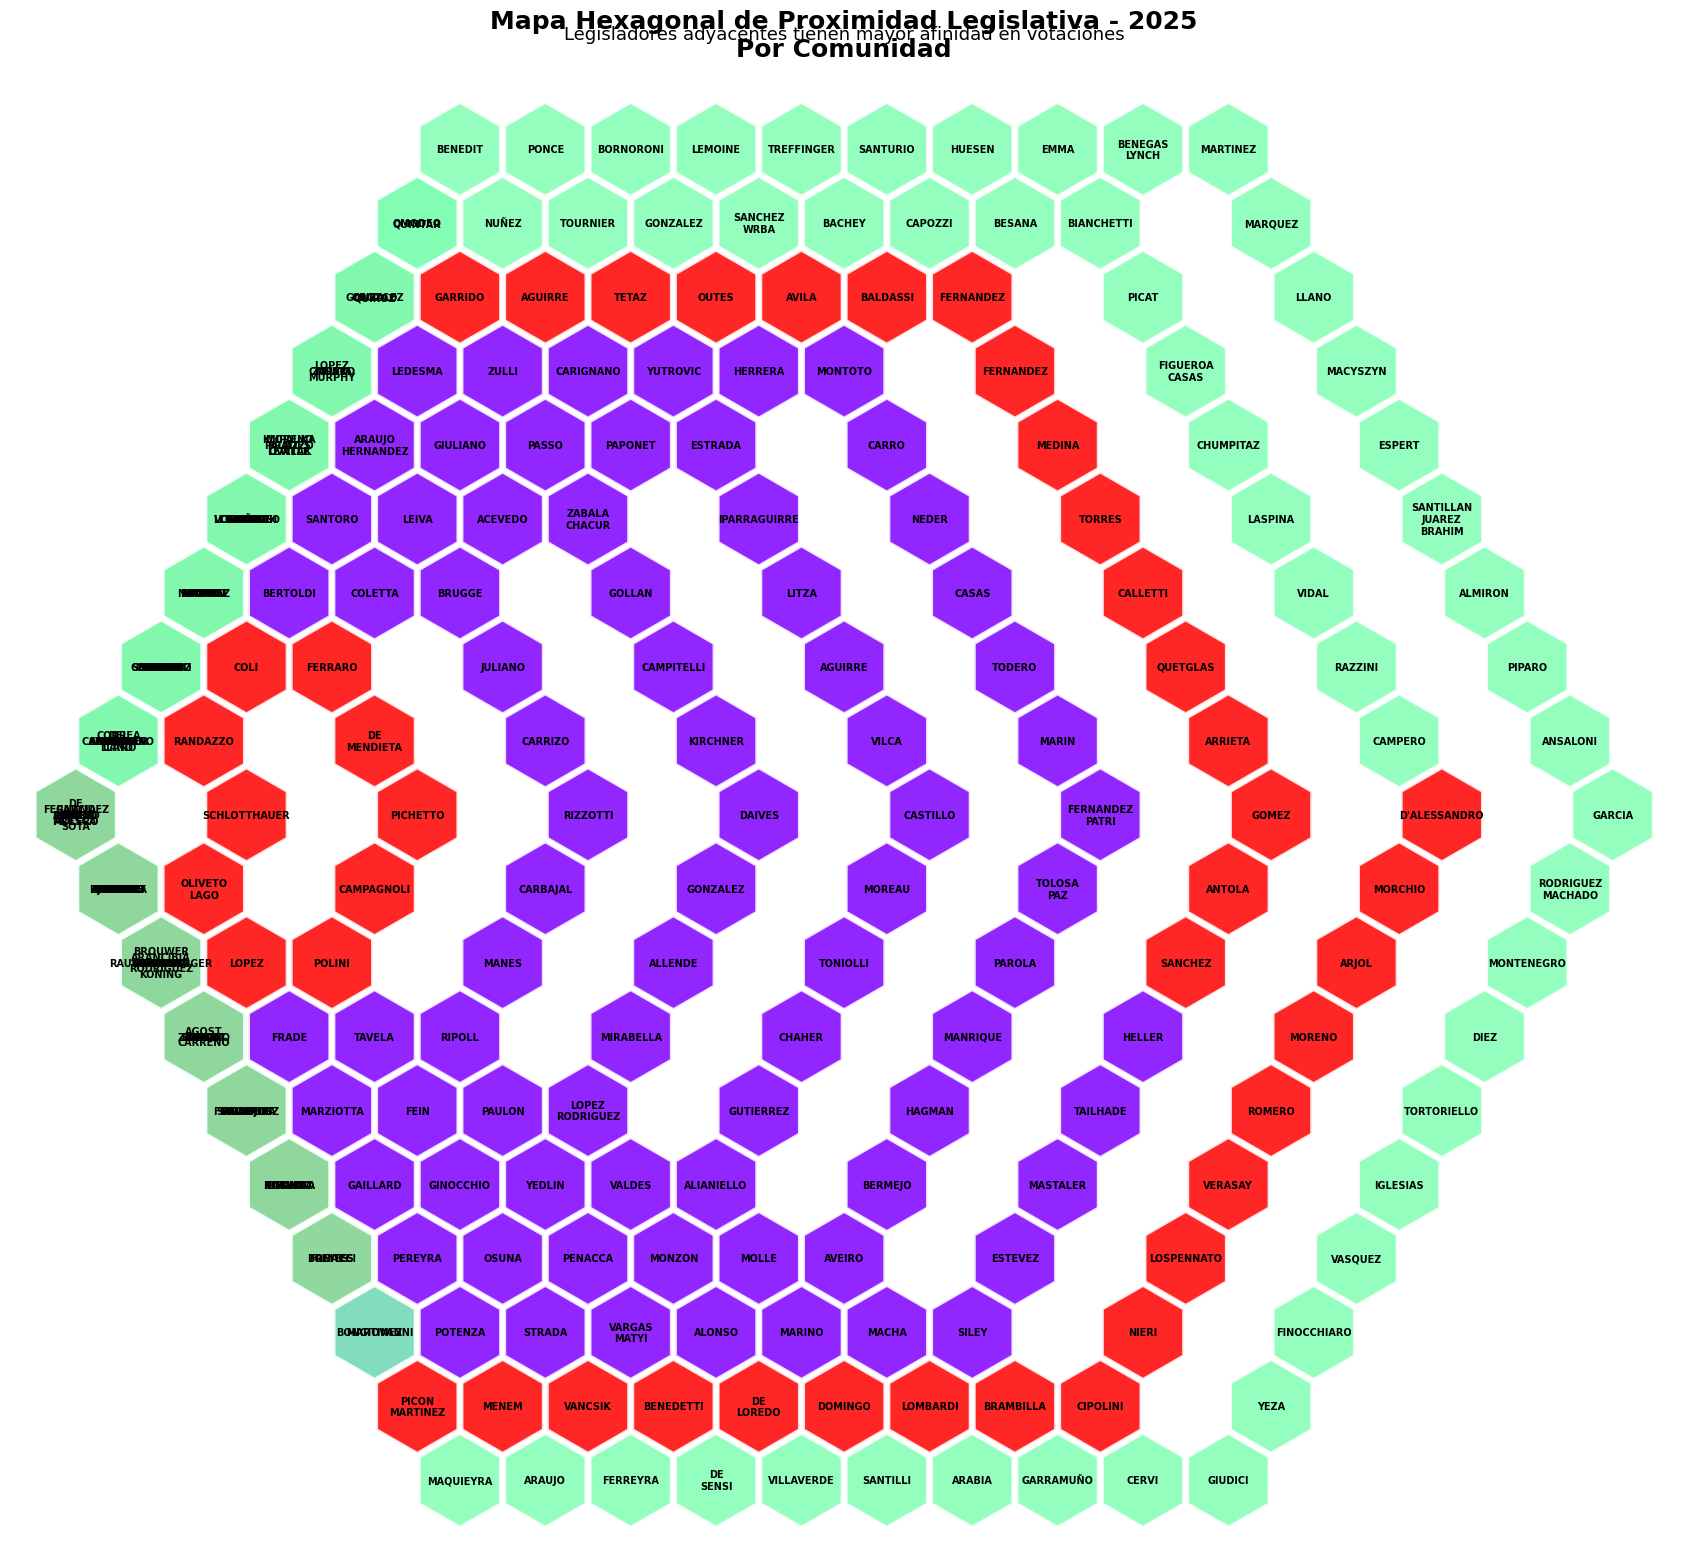

In [11]:
# Visualización por comunidad (colores del análisis de redes)
fig, ax = plt.subplots(figsize=(20, 16))

# Crear hexágonos
for _, row in df_asignaciones.iterrows():
    hex_patch = crear_hexagono(row['x'], row['y'], SIZE_HEX * 0.95)
    hex_patch.set_facecolor(row['color'])
    hex_patch.set_edgecolor('white')
    hex_patch.set_linewidth(2)
    hex_patch.set_alpha(0.85)
    ax.add_patch(hex_patch)
    
    # Agregar etiqueta
    ax.text(row['x'], row['y'], row['apellido'],
            ha='center', va='center',
            fontsize=7, fontweight='bold',
            color='black')

ax.set_xlim(df_asignaciones['x'].min() - 2, df_asignaciones['x'].max() + 2)
ax.set_ylim(df_asignaciones['y'].min() - 2, df_asignaciones['y'].max() + 2)
ax.set_aspect('equal')
ax.axis('off')

plt.title(f'Mapa Hexagonal de Proximidad Legislativa - {ANIO_ANALISIS}\nPor Comunidad',
          fontsize=18, fontweight='bold', pad=20)
plt.suptitle('Legisladores adyacentes tienen mayor afinidad en votaciones',
             fontsize=13, y=0.96)

plt.tight_layout()
plt.savefig(os.path.join(carpeta_redes, f'mapa_hexagonal_comunidad_{ANIO_ANALISIS}.png'),
            dpi=150, bbox_inches='tight')
plt.show()

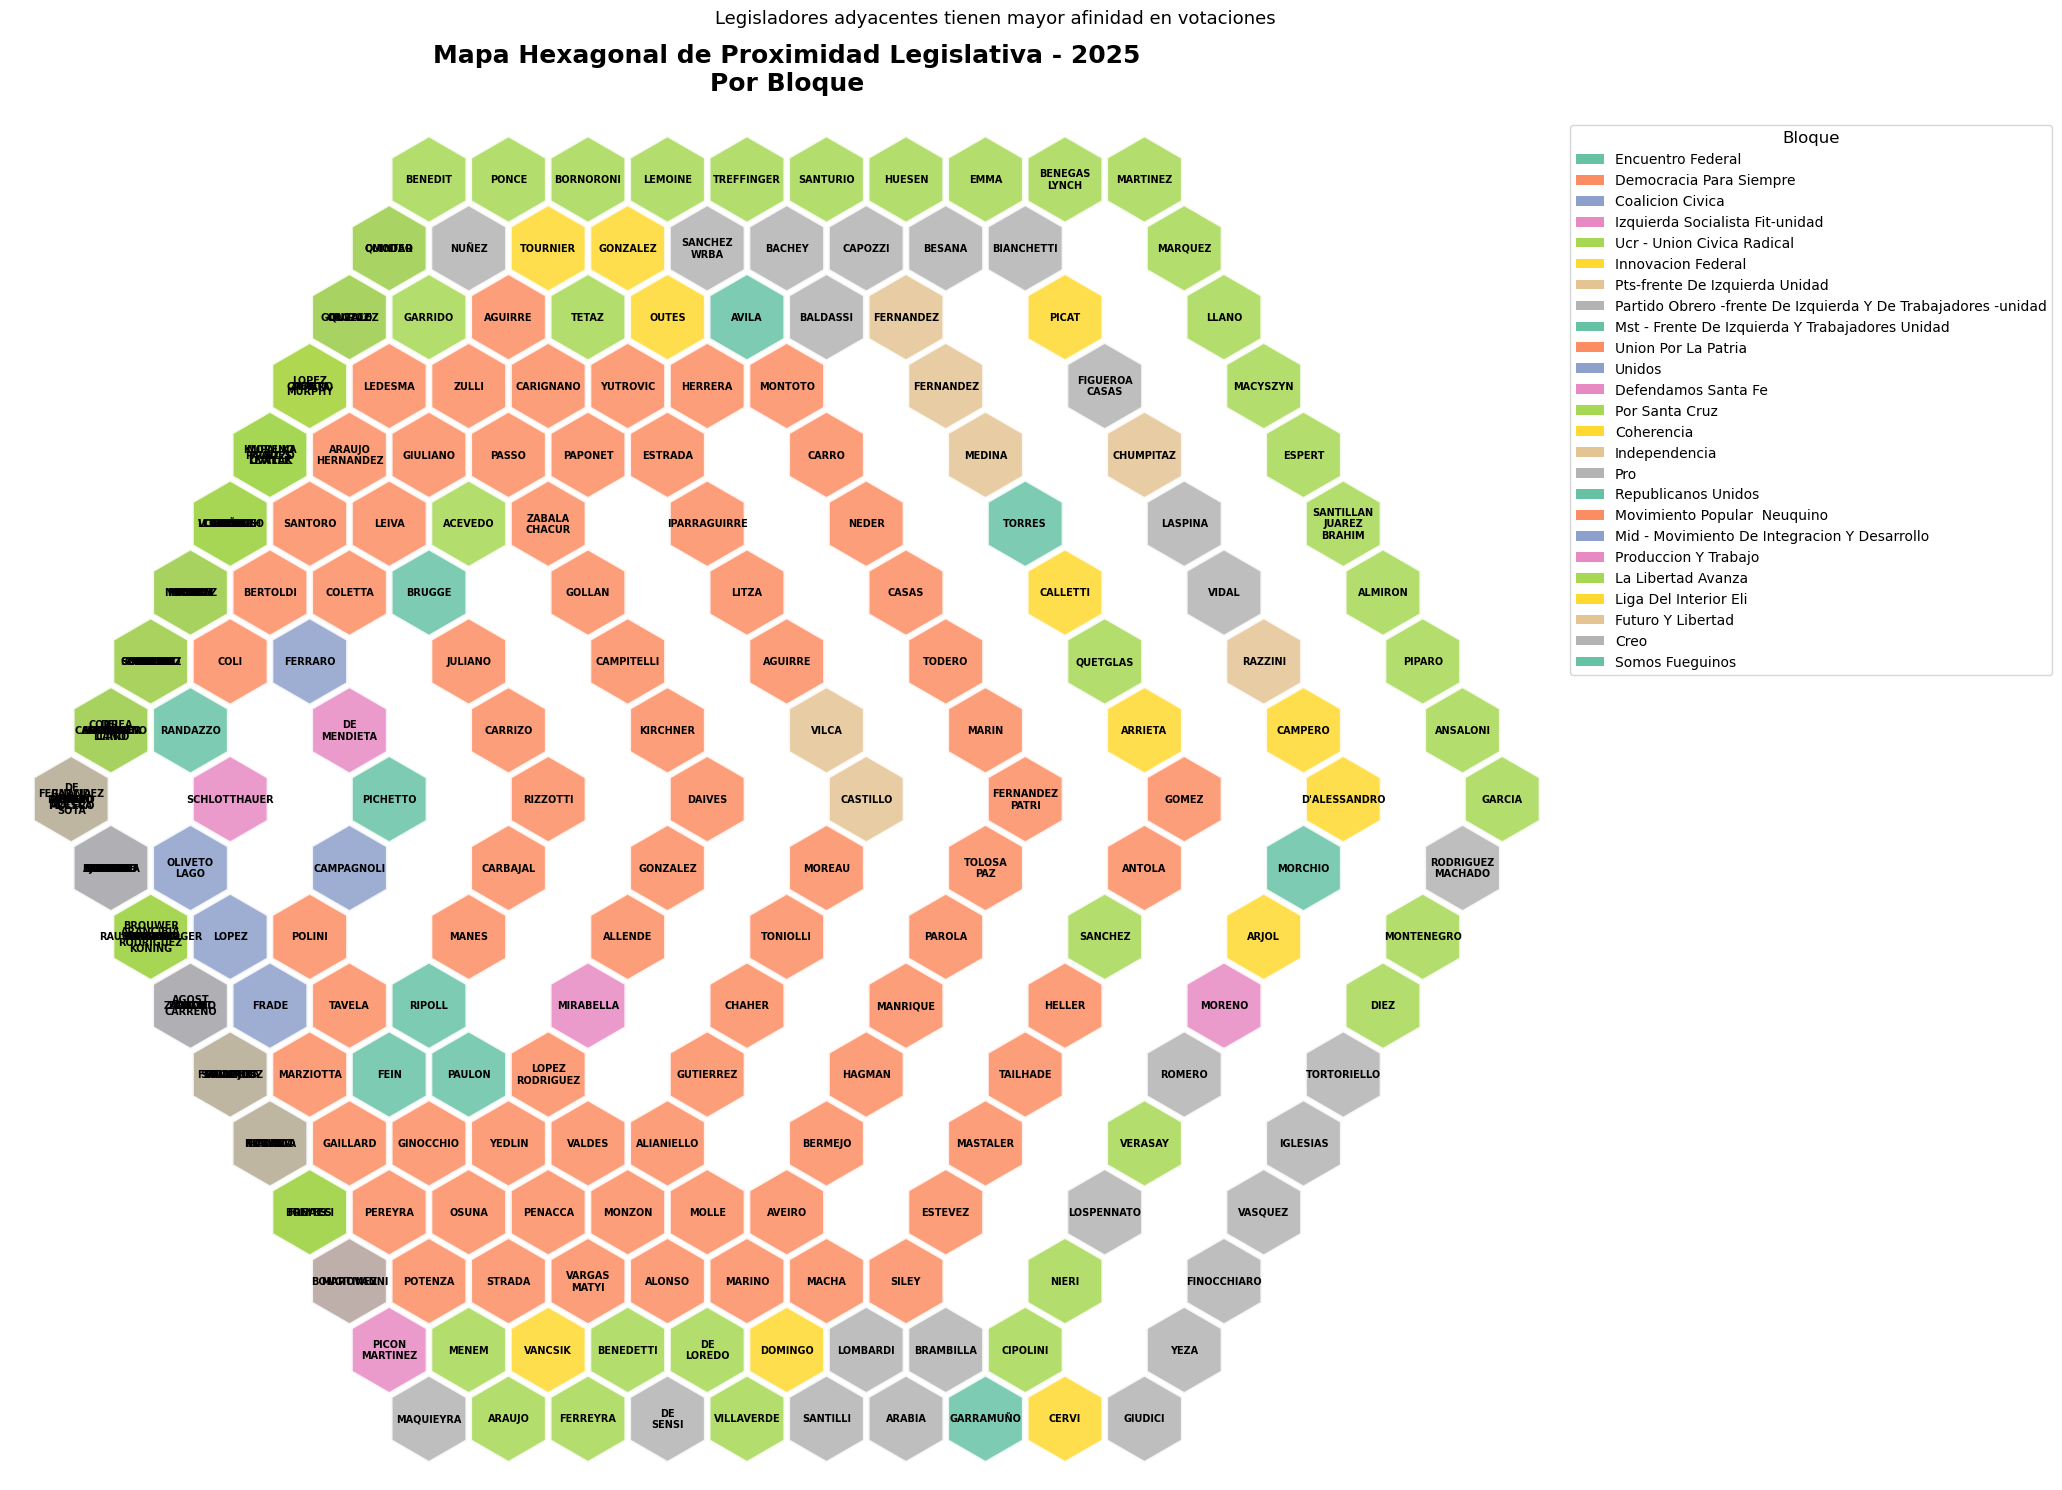

In [12]:
# Visualización por bloque
# Crear paleta de colores para bloques
bloques_unicos = df_asignaciones['bloque'].unique()
colores_bloques = sns.color_palette('Set2', n_colors=len(bloques_unicos))
mapa_colores_bloques = dict(zip(bloques_unicos, [f'#{int(r*255):02x}{int(g*255):02x}{int(b*255):02x}' for r, g, b in colores_bloques]))

fig, ax = plt.subplots(figsize=(20, 16))

for _, row in df_asignaciones.iterrows():
    hex_patch = crear_hexagono(row['x'], row['y'], SIZE_HEX * 0.95)
    hex_patch.set_facecolor(mapa_colores_bloques[row['bloque']])
    hex_patch.set_edgecolor('white')
    hex_patch.set_linewidth(2)
    hex_patch.set_alpha(0.85)
    ax.add_patch(hex_patch)
    
    ax.text(row['x'], row['y'], row['apellido'],
            ha='center', va='center',
            fontsize=7, fontweight='bold',
            color='black')

ax.set_xlim(df_asignaciones['x'].min() - 2, df_asignaciones['x'].max() + 2)
ax.set_ylim(df_asignaciones['y'].min() - 2, df_asignaciones['y'].max() + 2)
ax.set_aspect('equal')
ax.axis('off')

# Leyenda
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=mapa_colores_bloques[bloque], label=bloque)
                  for bloque in bloques_unicos]
ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1),
         fontsize=10, title='Bloque', title_fontsize=12)

plt.title(f'Mapa Hexagonal de Proximidad Legislativa - {ANIO_ANALISIS}\nPor Bloque',
          fontsize=18, fontweight='bold', pad=20)
plt.suptitle('Legisladores adyacentes tienen mayor afinidad en votaciones',
             fontsize=13, y=0.96)

plt.tight_layout()
plt.savefig(os.path.join(carpeta_redes, f'mapa_hexagonal_bloque_{ANIO_ANALISIS}.png'),
            dpi=150, bbox_inches='tight')
plt.show()